# Biacore SPR Example: Import a Result File and Prepare a Fitting Dataset

This notebook imports a Biacore T200 result file (`.blr`), shows the sample rack layout and the steps found in each cycle, and prepares the association and dissociation curves for fitting. It does not fit any model.

The data are surface plasmon resonance (SPR) sensorgrams of a Strep-tag peptide (*Streptag-Gly loop*) binding streptavidin on a CM5 chip: `SPR sensograms with Streptavidin_1.blr` from Vummidi *et al.*, Zenodo, [doi:10.5281/zenodo.5011513](https://doi.org/10.5281/zenodo.5011513), licensed CC-BY 4.0.

In [1]:
from pathlib import Path
import os
import sys
import tempfile
import numpy as np
import pandas as pd

cwd = Path.cwd().resolve()
repo_root = cwd if (cwd / "src" / "pykingenie").exists() else cwd.parent

for path in [repo_root / "src", repo_root / "notebooks"]:
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))

os.environ.setdefault("MPLCONFIGDIR", str(Path(tempfile.gettempdir()) / "pykingenie-matplotlib"))

from pykingenie import BiacoreExperiment, KineticsAnalyzer
from pykingenie.utils.plotting import plot_association_dissociation, plot_plate_info, plot_traces
from pykingenie.utils.palettes import VIRIDIS

try:
    from notebook_helpers import show_plotly_static as _show_plotly_static
except ImportError:
    _show_plotly_static = None

def show_plotly_static(fig, **kwargs):
    if _show_plotly_static is None:
        return fig
    try:
        return _show_plotly_static(fig, **kwargs)
    except Exception as exc:
        print(f"Static rendering skipped: {exc}")
        return fig

def show_experiment_traces(experiment, title, sensors=None, width=1000, height=500):
    sensors = experiment.sensor_names if sensors is None else sensors
    idx = [experiment.sensor_names.index(s) for s in sensors]
    colors = [VIRIDIS[int(i)] for i in np.linspace(0, len(VIRIDIS) - 1, len(idx))]
    fig = plot_traces(
        xs=[experiment.xs[i] for i in idx],
        ys=[experiment.ys[i] for i in idx],
        legends=sensors,
        colors=colors,
        show=[True] * len(idx),
        marker_size=1,
        line_width=2,
    )
    fig.update_layout(
        title={"text": title, "font": {"size": 22}},
        xaxis_title="Run time (s)",
        yaxis_title="Response (RU)",
        font={"size": 16},
    )
    show_plotly_static(fig, width=width, height=height)
    return fig

## Import the Biacore Result File

`read_blr` reads the file without the Biacore software. Each flow cell, and each reference-subtracted pair recorded by the instrument, becomes a sensor. Cycles are placed at their start in the run, so the gaps between cycles are times when no data were recorded.

In [2]:
blr_file = repo_root / "test_files" / "SPR_sensograms_with_Streptavidin_1.blr"

spr = BiacoreExperiment("streptavidin_run1")
spr.read_blr(str(blr_file))

print("Sensors:", spr.sensor_names)
print("Steps:", spr.no_steps)

Sensors: ['Fc3', 'Fc4', 'Fc4-3']
Steps: 84


Run, sensor chip and flow cell information from the file:

In [3]:
pd.Series(spr.exp_info, name="value").to_frame()

,value
Application,Biacore T200 Control Software
Version,2.0.2
RunType,Kinetics/Affinity
InstrumentId,2189971
Run_start,2017-09-21T19:27:47
Run_end,2017-09-21T21:48:50
Chip,CM5
Concentration_unit,µM
Fc1_ligand,Streptavidin
Fc1_immobilization_level_RU,807.219727


## Sample Rack Layout

Each rack position used by an injection appears once. Rows carry the rack: `R1 C` is row C of rack 1. `S` marks sample positions, `B` positions where every injection was 0 µM (buffer or blank), and `R` the regeneration solution. Hover over a position in the interactive figure to see its sample and concentration.

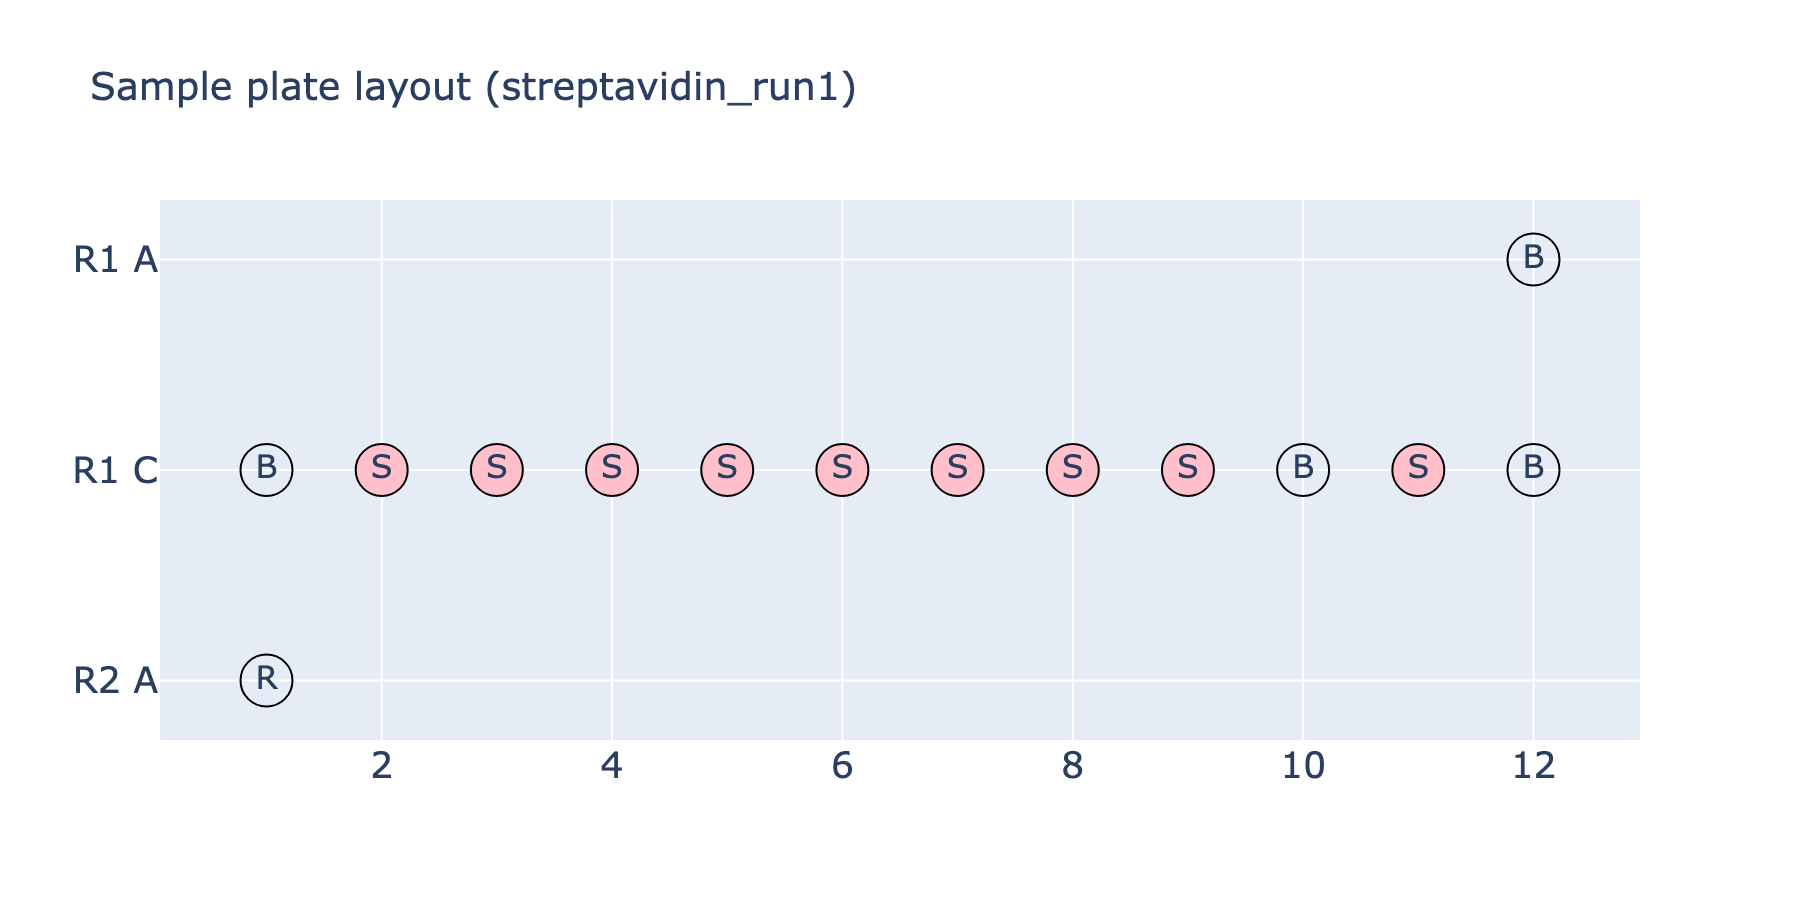

In [4]:
pyKinetics = KineticsAnalyzer()
pyKinetics.add_experiment(spr, "streptavidin_run1")

fig_plate = plot_plate_info(pyKinetics, "streptavidin_run1")
show_plotly_static(fig_plate, width=900, height=450)

The same information as a table:

In [5]:
pd.DataFrame({
    "Row": spr.sample_row,
    "Column": spr.sample_column,
    "Type": spr.sample_type,
    "Sample": spr.sample_id,
    "Concentration": spr.sample_conc_labeled,
})

,Row,Column,Type,Sample,Concentration
0,R1 A,12,BUFFER,buffer,0 µM
1,R1 C,1,BUFFER,Streptag-Gly loop,0 µM
2,R1 C,2,KSAMPLE,Streptag-Gly loop,0.78125 µM
3,R1 C,3,KSAMPLE,Streptag-Gly loop,1.5625 µM
4,R1 C,4,KSAMPLE,Streptag-Gly loop,3.125 µM
5,R1 C,5,KSAMPLE,Streptag-Gly loop,6.25 µM
6,R1 C,6,KSAMPLE,Streptag-Gly loop,12.5 µM
7,R1 C,7,KSAMPLE,Streptag-Gly loop,25 µM
8,R1 C,8,KSAMPLE,Streptag-Gly loop,50 µM
9,R1 C,9,KSAMPLE,Streptag-Gly loop,100 µM


## Steps

Each cycle is split into steps from its event log:

- `BASELINE`: buffer flow before and between injections;
- `ASSOC`: the sample injection;
- `DISASSOC`: from the end of the sample injection to the end of the report period;
- `KREGENERATION`: the regeneration injection.

`Start` is the run time in seconds, `Sample_position` the rack position of the injection, and `Column_location` the number of the association, used to match each association with its concentration.

In [6]:
spr.df_steps.head(12)

,#Step,Name,Type,Start,Cycle,Sample_position,Column_location,Loading_location
0,1,Cycle 1 Baseline,BASELINE,464.914996,1,,1,NaN
1,2,Cycle 1 Sample 1,ASSOC,528.214996,1,R1C12,1,0
2,3,Cycle 1 Dissociation,DISASSOC,648.314996,1,R1C12,1,NaN
3,4,Cycle 1 Baseline,BASELINE,888.314996,1,,1,NaN
4,5,Cycle 1 Regeneration 1,KREGENERATION,960.014996,1,R2A1,1,NaN
5,6,Cycle 1 Baseline,BASELINE,970.114996,1,,1,NaN
6,7,Cycle 2 Baseline,BASELINE,1035.859994,2,,2,NaN
7,8,Cycle 2 Sample 1,ASSOC,1099.159994,2,R1C12,2,0
8,9,Cycle 2 Dissociation,DISASSOC,1219.159994,2,R1C12,2,NaN
9,10,Cycle 2 Baseline,BASELINE,1459.259994,2,,2,NaN


In [7]:
spr.df_steps.pivot_table(index="Cycle", columns="Type", values="#Step", aggfunc="count").fillna(0).astype(int).T

Cycle,1,2,3,4,5,6,7,8,9,10,11,12,13,14
Type,,,,,,,,,,,,,,
ASSOC,1,1,1,1,1,1,1,1,1,1,1,1,1,1
BASELINE,3,3,3,3,3,3,3,3,3,3,3,3,3,3
DISASSOC,1,1,1,1,1,1,1,1,1,1,1,1,1,1
KREGENERATION,1,1,1,1,1,1,1,1,1,1,1,1,1,1


## Sensorgrams

`Fc3` is the reference flow cell (no ligand) and `Fc4` the streptavidin flow cell; both are absolute responses. `Fc4-3` is the reference-subtracted curve recorded by the instrument. The large dips are the regenerations. At 100 µM (cycle 12) the peptide also binds the reference flow cell, so `Fc4-3` drops and recovers only slowly over the following cycles.

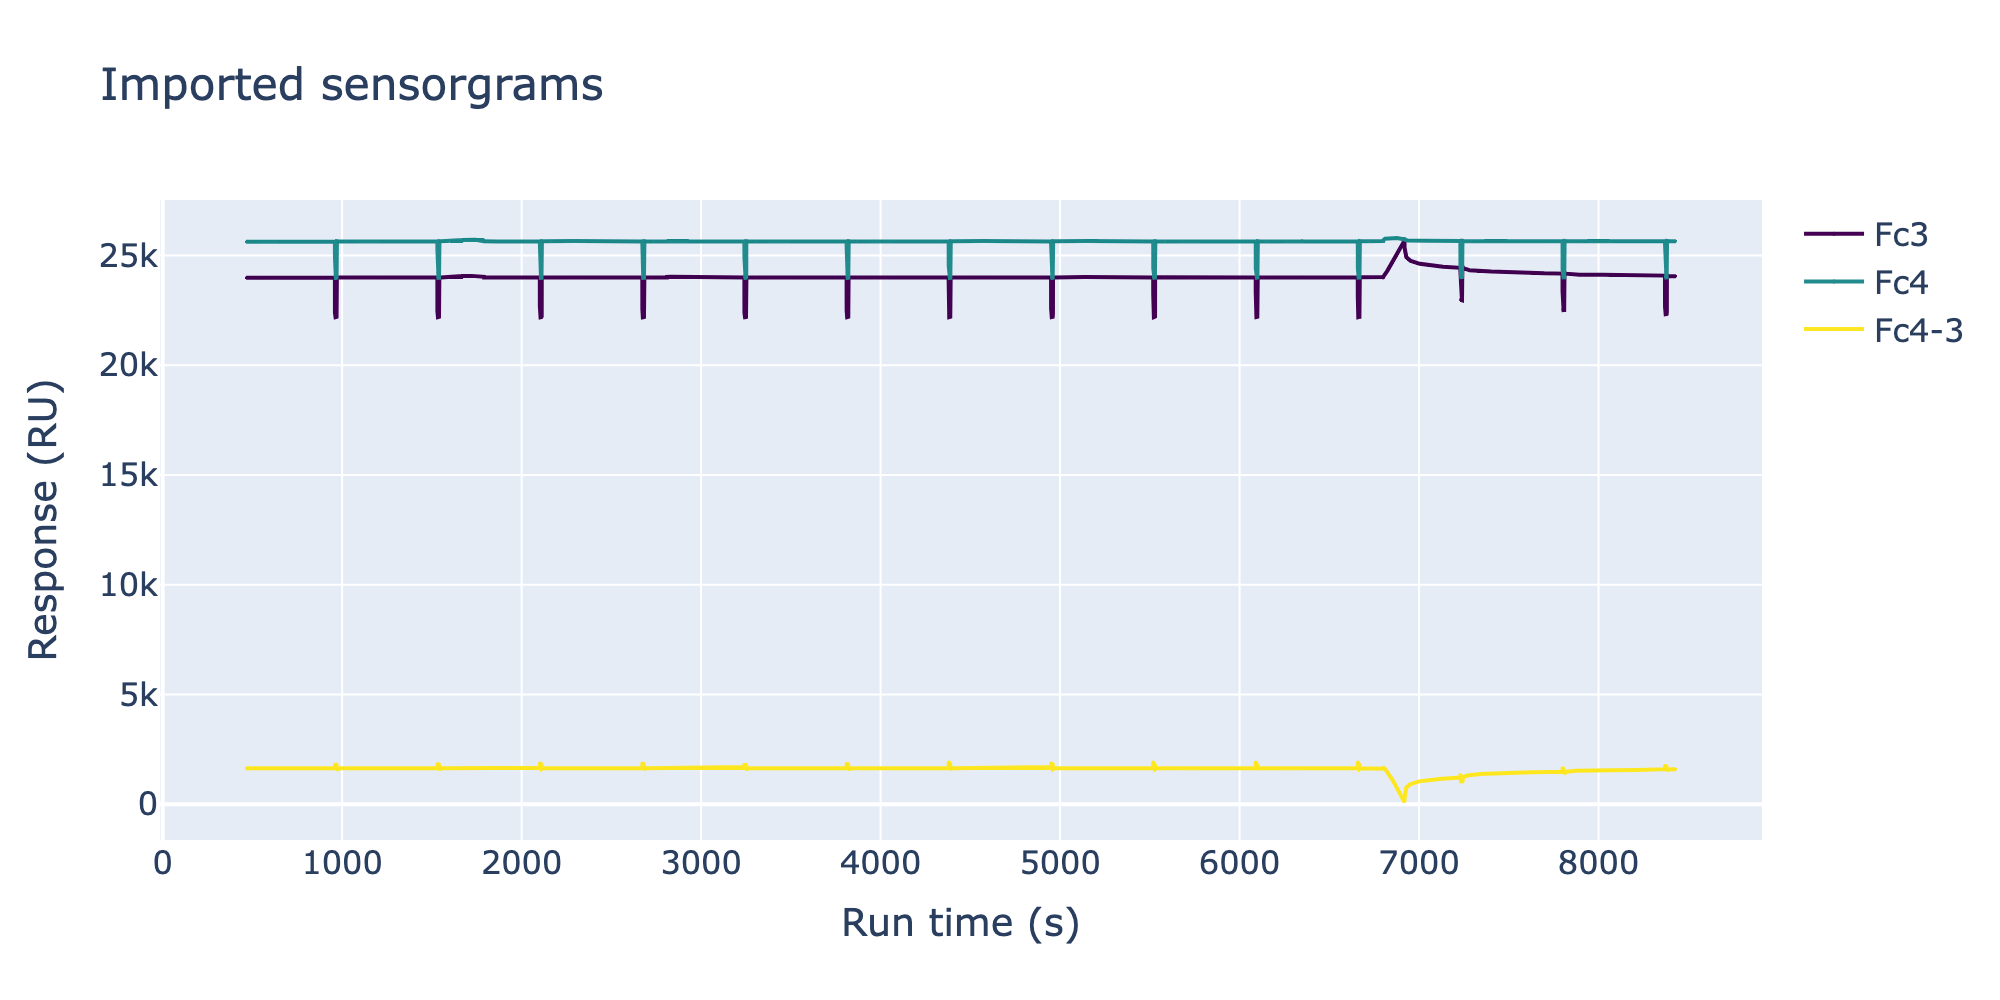

In [8]:
fig_raw = show_experiment_traces(spr, "Imported sensorgrams")

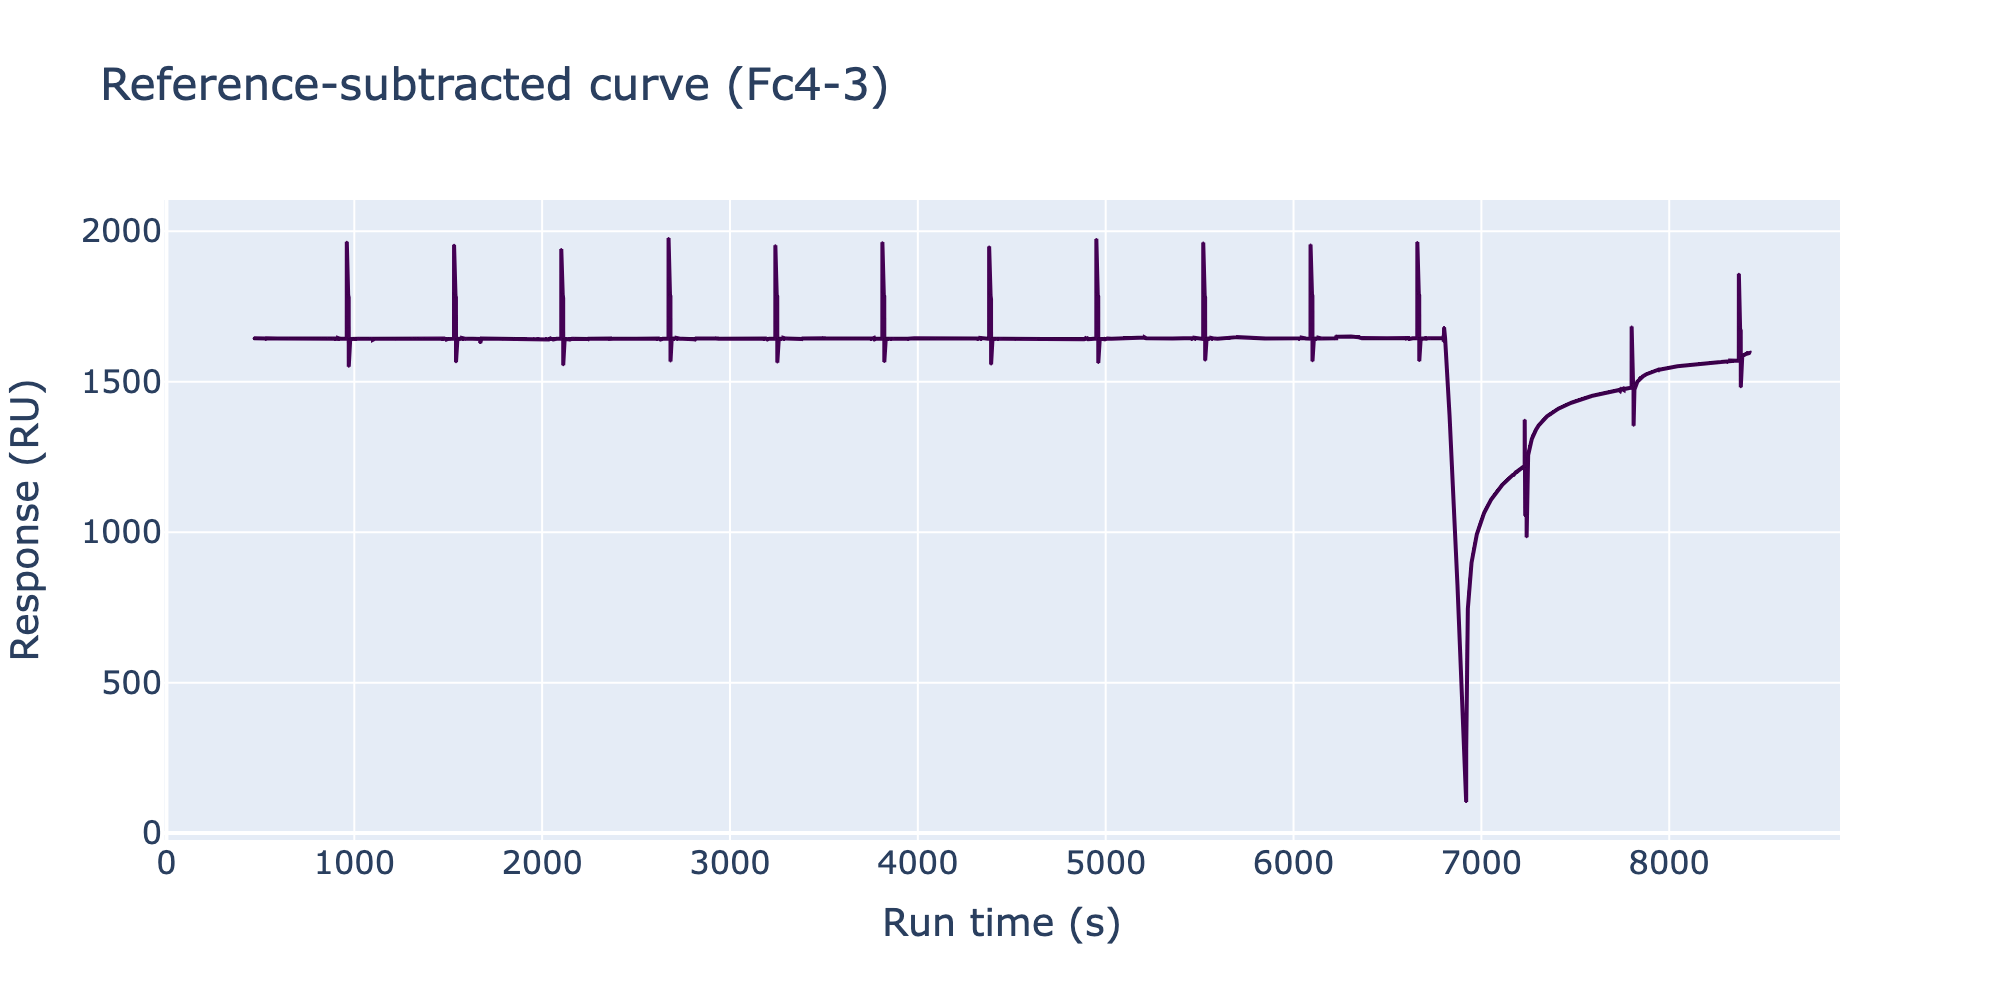

In [9]:
fig_subtracted = show_experiment_traces(spr, "Reference-subtracted curve (Fc4-3)", sensors=["Fc4-3"])

## Concentrations

One row per sensor and association, with the concentration converted to µM. The first three cycles are startup cycles with buffer, followed by a 0 µM blank, a two-fold dilution series from 0.78 to 100 µM, and repeats of 0 and 0.78 µM.

In [10]:
spr.ligand_conc_df[spr.ligand_conc_df["Sensor"] == "Fc4-3"]

,Sensor,Analyte_location,Concentration_micromolar,SampleID,Replicate,Loading_location,Experiment
28,Fc4-3,1,0.00000,buffer,1,0,streptavidin_run1
29,Fc4-3,2,0.00000,buffer,1,0,streptavidin_run1
30,Fc4-3,3,0.00000,buffer,1,0,streptavidin_run1
31,Fc4-3,4,0.00000,Streptag-Gly loop,1,0,streptavidin_run1
32,Fc4-3,5,0.78125,Streptag-Gly loop,1,0,streptavidin_run1
33,Fc4-3,6,1.56250,Streptag-Gly loop,1,0,streptavidin_run1
34,Fc4-3,7,3.12500,Streptag-Gly loop,1,0,streptavidin_run1
35,Fc4-3,8,6.25000,Streptag-Gly loop,1,0,streptavidin_run1
36,Fc4-3,9,12.50000,Streptag-Gly loop,1,0,streptavidin_run1
37,Fc4-3,10,25.00000,Streptag-Gly loop,1,0,streptavidin_run1


## Prepare the Dataset for Fitting

The associations of `Fc4-3` are aligned so each one starts at zero. Only the dilution series before the 100 µM injection is kept (`Analyte_location` 5 to 11, 0.78 to 50 µM): the 100 µM cycle and the two repeats after it are affected by binding to the reference flow cell. Rows with 0 µM are left out because they carry no binding information.

In [11]:
spr.align_association(["Fc4-3"])

pyKinetics = KineticsAnalyzer()
pyKinetics.add_experiment(spr, "streptavidin_run1")
pyKinetics.merge_ligand_conc_df()

conc_df = pyKinetics.combined_ligand_conc_df
selected_curves = conc_df[
    (conc_df["Sensor"] == "Fc4-3")
    & (conc_df["[Analyte] (μM)"] > 0)
    & (conc_df["Analyte_location"].astype(int) <= 11)
].copy()
selected_curves

,Sensor,[Analyte] (μM),SampleID,Select,Smax_ID,Analyte_location
32,Fc4-3,0.78125,Streptag-Gly loop,True,1,5
33,Fc4-3,1.56250,Streptag-Gly loop,True,1,6
34,Fc4-3,3.12500,Streptag-Gly loop,True,1,7
35,Fc4-3,6.25000,Streptag-Gly loop,True,1,8
36,Fc4-3,12.50000,Streptag-Gly loop,True,1,9
37,Fc4-3,25.00000,Streptag-Gly loop,True,1,10
38,Fc4-3,50.00000,Streptag-Gly loop,True,1,11


In [12]:
pyKinetics.init_fittings()
messages = pyKinetics.generate_fittings(selected_curves)

print("\n".join(messages))
print(pyKinetics.fittings_names)

Creating a new fitting object for sample: Streptag-Gly loop
['Streptag-Gly loop']


Each fitting dataset holds the association and dissociation curves of one sample, with their concentrations:

In [13]:
fitter = pyKinetics.fittings[pyKinetics.fittings_names[0]]

pd.DataFrame({
    "Concentration (µM)": fitter.lig_conc_lst,
    "Association points": [len(y) for y in fitter.assoc_lst],
    "Association length (s)": [round(t[-1] - t[0], 1) for t in fitter.time_assoc_lst],
    "Dissociation points": [len(y) for y in fitter.disso_lst],
    "Dissociation length (s)": [round(t[-1] - t[0], 1) for t in fitter.time_disso_lst],
})

,Concentration (µM),Association points,Association length (s),Dissociation points,Dissociation length (s)
0,0.78125,1200,119.9,2401,240.0
1,1.56250,1200,119.9,2401,240.0
2,3.12500,1200,119.9,2401,240.0
3,6.25000,1201,120.0,2400,239.9
4,12.50000,1201,120.0,2400,239.9
5,25.00000,1201,120.0,2400,239.9
6,50.00000,1201,120.0,2400,239.9


## Curves Ready for Fitting

The association and dissociation curves of the dataset. The short spikes at the start and end of the injection come from the injection valve switching. Steady-state and kinetic fits can be run next with `submit_steady_state_fitting` and `submit_kinetics_fitting`.

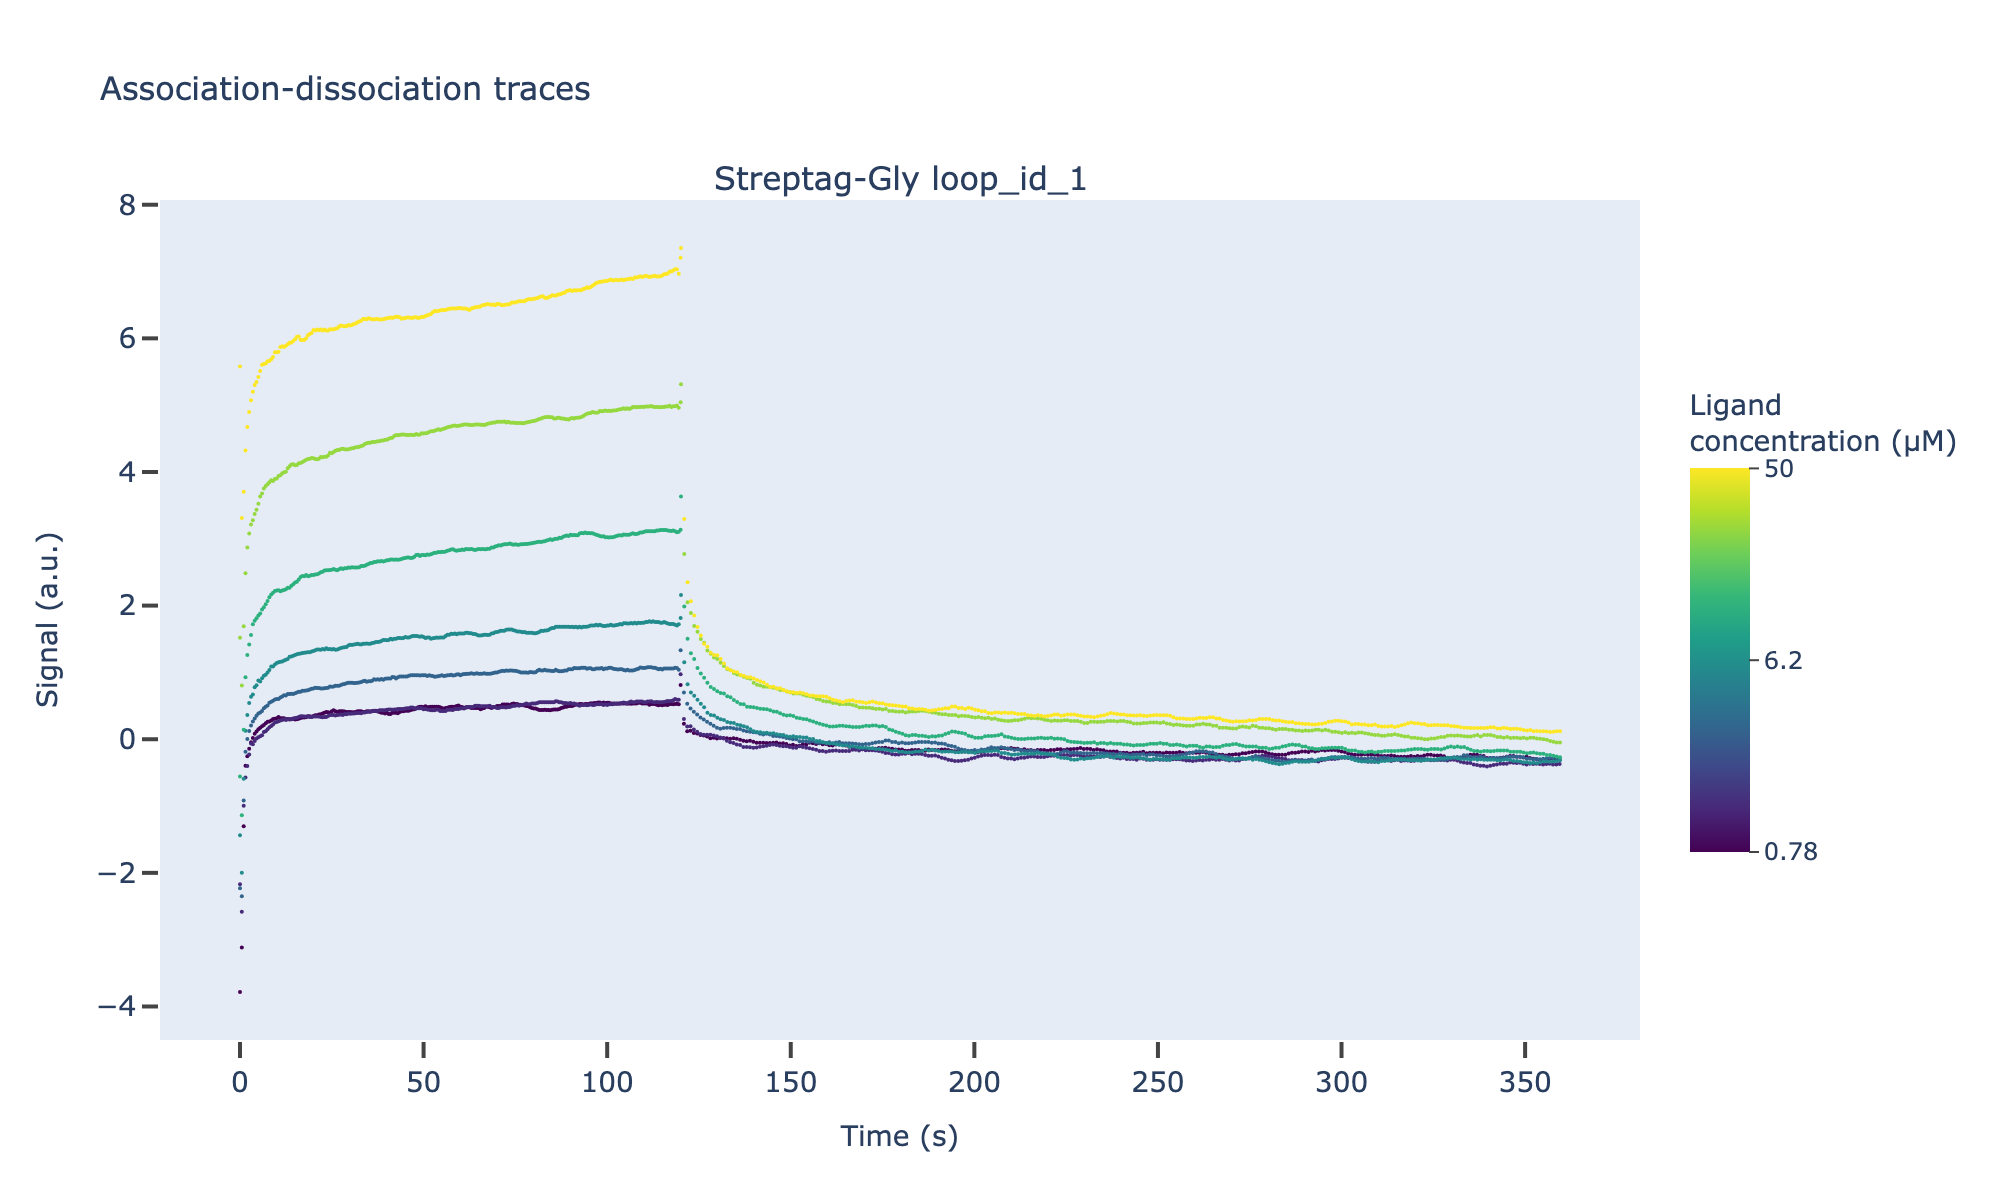

In [14]:
fig_dataset = plot_association_dissociation(
    pyKinetics,
    plot_width=12,
    plot_height=7,
    marker_size=2,
)
show_plotly_static(fig_dataset, width=1000, height=600)